# Heart Disease Prediction — Exploratory Data Analysis

**Course:** Machine Learning Operations (MLOps) - AIMLCZG523  
**Assignment:** Assignment 01  
**Dataset:** Heart Disease - UCI Machine Learning Repository

## Objective

The objective of this project is to develop an end-to-end machine learning
solution for predicting the presence or absence of heart disease using
patient health attributes.

This notebook performs data acquisition validation, data quality analysis,
target transformation, exploratory data analysis, and preparation of the
dataset for subsequent machine learning experiments.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

FIGURE_DIR = Path("../reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("EDA environment ready")

EDA environment ready


## 1. Data Acquisition and Loading

The Heart Disease dataset was obtained from the official UCI Machine
Learning Repository (Dataset ID 45).

A reproducible data acquisition script is maintained in
`src/download_data.py`. The original downloaded dataset is stored under
`data/raw/` so that raw source data remains separate from processed data.

In [3]:
import os

print("Current working directory:")
print(os.getcwd())

Current working directory:
/home/s2025ae05100/workspace/heart-disease-mlops


In [4]:
print("Files/folders here:")
print(os.listdir("."))

Files/folders here:
['src', 'notebooks', 'models', 'requirements.txt', '01_eda.ipynb', 'api', 'data', '.ipynb_checkpoints', 'deployment', 'screenshots', 'tests', 'reports']


In [5]:
from pathlib import Path

print("data/raw exists:", Path("data/raw").exists())
print("CSV exists:", Path("data/raw/heart_disease.csv").exists())
print("../data/raw exists:", Path("../data/raw").exists())
print("../data/raw CSV exists:", Path("../data/raw/heart_disease.csv").exists())

data/raw exists: True
CSV exists: True
../data/raw exists: False
../data/raw CSV exists: False


In [6]:
from pathlib import Path

DATA_PATH = Path("data/raw/heart_disease.csv")

print("Reading dataset from:", DATA_PATH.resolve())

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Reading dataset from: /home/s2025ae05100/workspace/heart-disease-mlops/data/raw/heart_disease.csv
Dataset loaded successfully.
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [7]:
Path("data/raw/heart_disease.csv")

PosixPath('data/raw/heart_disease.csv')

In [8]:
print("Number of observations:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Number of observations: 303
Number of columns: 14

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [11]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


### Duplicate Analysis

Duplicate observations were checked before preprocessing. No duplicate
records were detected in the downloaded dataset, so duplicate removal was
not required.

## 2. Missing Value Analysis

Missing values were examined before model development because incomplete
observations can affect model training and production inference.

In [12]:
missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().mean() * 100
).round(2)

missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_percentage
})

missing_table.sort_values(
    by="Missing Count",
    ascending=False
)

,Missing Count,Missing Percentage (%)
ca,4,1.32
thal,2,0.66
cp,0,0.00
trestbps,0,0.00
age,0,0.00
sex,0,0.00
fbs,0,0.00
chol,0,0.00
restecg,0,0.00
thalach,0,0.00


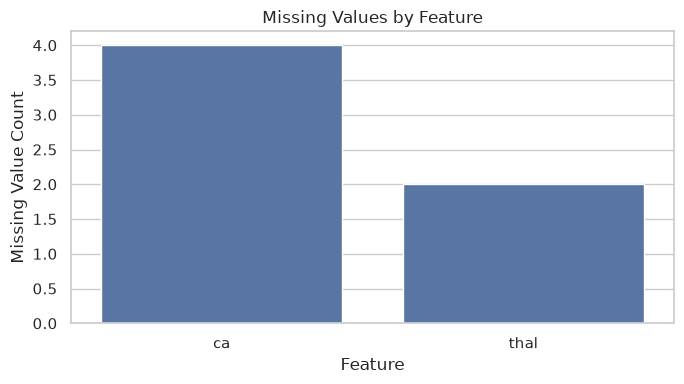

In [13]:
missing_only = missing_table[
    missing_table["Missing Count"] > 0
]

plt.figure(figsize=(7, 4))

sns.barplot(
    x=missing_only.index,
    y=missing_only["Missing Count"]
)

plt.title("Missing Values by Feature")
plt.xlabel("Feature")
plt.ylabel("Missing Value Count")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "missing_values.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

Missing observations were identified in the `ca` and `thal` features.
Since the dataset contains only 303 observations, deleting incomplete
records would unnecessarily reduce the available training data.

The missing values will therefore be handled using imputers inside the
scikit-learn preprocessing pipeline. This also ensures that identical
preprocessing logic is applied during model training and production
inference.

## 3. Target Variable Analysis

The original UCI Heart Disease dataset uses the `num` variable to represent
the diagnosis of heart disease. The assignment requires a binary
classification problem representing the presence or absence of heart
disease.

In [14]:
original_target = (
    df["num"]
    .value_counts()
    .sort_index()
)

print("Original target distribution:")
print(original_target)

Original target distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [15]:
df["target"] = (df["num"] > 0).astype(int)

print("Binary target created successfully.")

pd.crosstab(
    df["num"],
    df["target"],
    rownames=["Original num"],
    colnames=["Binary target"]
)

Binary target created successfully.


Binary target,0,1
Original num,,
0,164,0
1,0,55
2,0,36
3,0,35
4,0,13


### Binary Target Definition

The target variable was transformed as follows:

- **0 — No Heart Disease:** original `num = 0`
- **1 — Heart Disease Present:** original `num > 0`

The original `num` variable will be removed before model training because
the binary target is directly derived from it. Retaining `num` as an input
feature would introduce target leakage.

In [16]:
class_counts = (
    df["target"]
    .value_counts()
    .sort_index()
)

class_percentages = (
    df["target"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages
})

class_summary.index = [
    "No Heart Disease",
    "Heart Disease"
]

class_summary

,Count,Percentage (%)
No Heart Disease,164,54.13
Heart Disease,139,45.87
